# PHYS 106 Modern Physics, Midterm 1: corrections in SymPy and Lean

This notebook walks back through the handwritten work on a four-page scan of Midterm 1
(Physics 106, Dr. Jensen, Fall 2026) and explains how to fix each part. It is a study guide,
not an answer key: for every part it shows the physics, the symbolic algebra, the units, a
numerical check, and what the result means.

**Teaching pattern used in every part:** quantity → equation → isolated variable → units → meaning.

**Four kinds of claim are kept separate:**

| Label | What it means | What it does *not* mean |
|---|---|---|
| **Symbolic derivation** (SymPy) | The algebra from the stated model is correct. | The model is the right physics. |
| **Numerical evaluation** | Numbers substituted with CODATA constants and units tracked. | The inputs were read correctly from the exam. |
| **Physical interpretation** | Why the answer makes sense (signs, limits, orders of magnitude). | A proof. |
| **Formal proof** (Lean 4 + Mathlib) | A machine-checked algebraic or arithmetic statement, but only if `lake env lean` succeeds (§8). | That the physics model is true. |

A SymPy `simplify` that returns the expected expression is **not** a physical proof.

In [1]:
import sympy as sp
sp.init_printing(use_unicode=True)

import re
import shutil
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sympy.physics import units as u
from sympy.physics.units.systems.si import SI

pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 200)
print("sympy", sp.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

sympy 1.14.0 | numpy 2.4.4 | pandas 2.3.3


In [2]:
def teach(part, quantity, equation, solve_for, units, meaning):
    '''quantity -> equation -> isolated variable -> units -> meaning'''
    display(Markdown(f"**[{part}] Quantity:** {quantity}"))
    print("Equation:")
    display(equation)
    isolated = sp.solve(equation, solve_for, dict=False)
    print(f"Isolated for {solve_for}:")
    for sol in isolated:
        display(sp.Eq(solve_for, sol))
    print("Units:", units)
    print("Meaning:", meaning)
    return isolated


def dimension_of(q):
    '''SI dimension of a sympy quantity expression; raises ValueError on mixed-dimension sums.'''
    return SI._collect_factor_and_dimension(q)[1]


def to(q, unit, digits=6):
    '''Convert to `unit` and return (exact, float) for printing.'''
    exact = u.convert_to(q, unit)
    return exact, sp.N(exact, digits)

## 1. Source transcription and uncertainty notes

**Source:** `Phys106 Fall2026 Modern pHysics exam 1 CamScanner 10-28-26 08.01.pdf` (4 pages, viewed
page by page). Page 1 is the printed cover page. Pages 2–4 hold handwritten work plus the grader's
red-ink comments. **The printed problem statements, diagrams, graphs, and multiple-choice options
are not in the scan.** Anything that depends on them is marked `MISSING_SOURCE_*`. The student ID on
the cover is left out on purpose.

**Page 1 (cover):** course header, an xkcd comic (#3043, muon time dilation), and the exam rules.
The rules say *"This exam consists of two problems"*, yet the work covers three (Q1, Q2, Q3).
This is probably a template leftover. Flagged, not resolved.

| Part | Points (red) | Legible handwritten work | Grader's red comment |
|---|---|---|---|
| Q1 total | 18 | — | — |
| Q1.1 | 5 | "2 eruptions are simultaneous", d = 600 km; sketch: Mt. Newton (B) left, Alex middle, Mt. E right, Charlie → v = 0.8c. "no work. Answer: a" | ✓ |
| Q1.2 | 8 | Distance Mt.N–Mt.E in Charlie's frame: L′ = ℓ/γ, γ = 1/√(1−β²), β = v/c; L′ = 600 km / √(1 − 0.8c/c) = 268.328 km. Side note: 600/(.8c) = 1/500 sec | "I think you forgot the square?" |
| Q1.3 | 0 | "is simultaneous?" s² = c²(Δt)² − (Δx)²; s² = c²(1/500)² − (600 km)²; s = √0 = 0; "True simultaneous s = 0" | "So are they, according to Charlie?" / "Spacetime interval doesn't help us here! Why?" / "no, that would mean Δx = 0 too" |
| Q1.4 | 5 | Sketch: Charlie → 0.8c, rock ← .4c. Also wrote E_i = E_f, p_i = p_f. u′ = (u−v)/(1−uv/c²); u′ = ((.4c) − (0.8))/(1 − (.4c)(0.8)/c²); **u′ = −0.588 m/s** | "Careful w. direction (+/−)"; sketch: "should look like > 0.8c?" |
| Q2 total | 18 | — | — |
| Q2.1 | 5 | λ = 178 nm; find v_max; K_max = hf − φ; ½mv² − ½mv_i² = h(178 nm) − φ; 1.60·10⁻¹⁹ C (5.7 V); v_max = √(1.6·10⁻¹⁹·5.7 / (½·9.11·10⁻³¹)); **v_max = 1.41·10⁶ m/s** | ✓ on K_max = hf − φ; "?" on 5.7 V; "at what potential is qΔV = K_max?" |
| Q2.2 | 8 | φ = hf − ½mv²; φ = 6.63·10⁻³⁴ J·s (178 nm) − ½(9.11·10⁻³¹ kg)(1.41·10⁶)²; **φ = −9.05E−19** | "not f" (circling 178 nm); "fix from a." |
| Q2.3 | 5 | Find P: P = (∂N/∂t) hf = Rhf = ∂E/∂t = ∂/∂t(6.63·10⁻³⁴ J·s · 178 nm) = ∂N/∂t (1.18·10⁻⁴⁰) | "Find R from the graph" |
| Q2.4 | 0 | Boxed "C", crossed out | — |
| Q3 total | 11 | — | — |
| Q3.1 | 5 | Boxed "C"; F = qE + q(v × B) | ✓ |
| Q3.2 | 6 | Sketch: B up, v right, F down-left (oblique, read here as out of page). (a) ~~positive~~ positive, negative. (b) ~~out of the page~~ down, out of page. (c) ~~right~~ into page, right | ✓ on "positive", "negative", "down", "into page"; red circles on "out of page" and "right" |
| Q3.3 | 0 | 200,000 Volts/m = \|E\| ⊥ \|B\| = 0.030 T; "Find v" (no further work) | — |
| Q3.4 | 0 | "10 eV Find photon wavelengths"; KE = 10 eV; E_n = −13.60 eV/n²; 10 eV = −13.60 eV/n²; n = √1 → boxed 3 | "only for hydrogen – use the energy diagram" |

**Uncertainty notes**
* **Q2.1, the 5.7 V:** the grader's "?" and *"at what potential is qΔV = K_max?"* mean 5.7 V may
  **not** be the stopping potential. It may be the potential at a different point on a graph or
  setup that isn't in the scan. Below, 5.7 V is treated as V_s **as a stated assumption** (status
  `ASSUMPTION`).
* **Q3.2:** the sub-part prompts and figure are missing, and the red circles are ambiguous (they
  could mean "wrong" or just "noted"). The direction method is taught in general. These answers are
  not re-graded.
* **Q3.3:** the prompt is missing. The velocity-selector reading (no deflection, E ⊥ B ⊥ v) is an
  assumption based on "|E| ⊥ |B|, Find v".
* **Q3.4:** the word is "wavelength**s**" (plural), and the grader says *use the energy diagram*.
  The full answer needs `MISSING_SOURCE_ENERGY_DIAGRAM`. The 124 nm result below covers only the
  10 eV photon itself.
* **Q1.1, Q2.4, Q3.1:** multiple-choice options are missing (`MISSING_SOURCE_CHOICES`).

In [3]:
MISSING_SOURCE_CHOICES_Q1_1 = None   # answer options for Q1.1 (student chose "a", marked correct)
MISSING_SOURCE_GRAPH_Q2_3 = None     # graph needed to read R = dN/dt (photon rate)
MISSING_SOURCE_PROMPT_Q2_4 = None    # entire Q2.4 prompt + choices (student boxed "C", crossed out)
MISSING_SOURCE_CHOICES_Q3_1 = None   # answer options for Q3.1 (student chose "C", marked correct)
MISSING_SOURCE_FIGURE_Q3_2 = None    # field/velocity figure and sub-part prompts for Q3.2
MISSING_SOURCE_ENERGY_DIAGRAM_Q3_4 = None  # energy-level diagram for Q3.4, list of levels in eV

score = pd.DataFrame([
    ("Q1.1", 5, "a", "check", "correct; choices not in scan"),
    ("Q1.2", 8, "268.328 km", "forgot the square?", "360 km"),
    ("Q1.3", 0, "s = 0, 'true simultaneous'", "interval doesn't help; s=0 would need dx=0", "not simultaneous for Charlie; |dt'| = 2.67 ms, Mt. E first"),
    ("Q1.4", 5, "-0.588 m/s", "careful with direction; should look like >0.8c", "-0.909c (= -10/11 c)"),
    ("Q2.1", 5, "1.41e6 m/s", "? on 5.7 V", "1.416e6 m/s IF Vs = 5.7 V"),
    ("Q2.2", 8, "-9.05e-19 (J)", "not f; fix from a", "phi = 1.27 eV = 2.03e-19 J IF Vs = 5.7 V"),
    ("Q2.3", 5, "dN/dt (1.18e-40)", "find R from the graph", "P = R h f; R needs MISSING_SOURCE_GRAPH"),
    ("Q2.4", 0, "C (crossed out)", "", "MISSING_SOURCE_PROMPT"),
    ("Q3.1", 5, "C", "check", "correct; choices not in scan"),
    ("Q3.2", 6, "pos/neg; down/out; into/right", "partial checks, circles", "method below; figure missing"),
    ("Q3.3", 0, "(blank)", "", "v = E/B = 6.67e6 m/s (velocity-selector assumption)"),
    ("Q3.4", 0, "n = 3 via E_n = -13.6/n^2", "only for hydrogen; use the energy diagram", "lambda(10 eV photon) = 124 nm; full answer needs diagram"),
], columns=["part", "points_awarded", "student_answer", "grader_note", "corrected_or_needed"])
display(score)
print("Totals by problem:", score.assign(q=score.part.str[:2]).groupby("q").points_awarded.sum().to_dict())

,part,points_awarded,student_answer,grader_note,corrected_or_needed
0,Q1.1,5,a,check,correct; choices not in scan
1,Q1.2,8,268.328 km,forgot the square?,360 km
2,Q1.3,0,"s = 0, 'true simultaneous'",interval doesn't help; s=0 would need dx=0,"not simultaneous for Charlie; |dt'| = 2.67 ms, Mt. E first"
3,Q1.4,5,-0.588 m/s,careful with direction; should look like >0.8c,-0.909c (= -10/11 c)
4,Q2.1,5,1.41e6 m/s,? on 5.7 V,1.416e6 m/s IF Vs = 5.7 V
5,Q2.2,8,-9.05e-19 (J),not f; fix from a,phi = 1.27 eV = 2.03e-19 J IF Vs = 5.7 V
6,Q2.3,5,dN/dt (1.18e-40),find R from the graph,P = R h f; R needs MISSING_SOURCE_GRAPH
7,Q2.4,0,C (crossed out),,MISSING_SOURCE_PROMPT
8,Q3.1,5,C,check,correct; choices not in scan
9,Q3.2,6,pos/neg; down/out; into/right,"partial checks, circles",method below; figure missing


Totals by problem: {'Q1': 18, 'Q2': 18, 'Q3': 11}


## 2. Constants and unit conventions

All constants are **exact SI values** (2019 SI redefinition: h, c, e are exact by definition)
stored as SymPy `Rational`s. Decimals appear only at the final evaluation step. The electron
mass is CODATA 2022 (measured, not exact). The exam used rounded values (h = 6.63e-34,
e = 1.60e-19, m = 9.11e-31). Section 7 shows that this rounding doesn't change any conclusion.

Relativity parts also use **c = 1 units** where helpful: velocities as fractions of c, and times
written as c·t in km, so β = 4/5 and γ = 5/3 stay exact.

In [4]:
c_SI  = sp.Integer(299792458) * u.meter / u.second                  # exact
h_SI  = sp.Rational(662607015, 10**42) * u.joule * u.second          # exact
e_SI  = sp.Rational(1602176634, 10**28) * u.coulomb                  # exact
me_SI = sp.Rational(91093837139, 10**41) * u.kilogram                # CODATA 2022
eV    = sp.Rational(1602176634, 10**28) * u.joule                    # 1 eV, exact
hbar_SI = h_SI / (2 * sp.pi)

for name, q in [("c", c_SI), ("h", h_SI), ("e", e_SI), ("m_e", me_SI), ("1 eV", eV)]:
    print(f"{name:5s} = {sp.N(q, 10)}")
hc_over_eV = u.convert_to(h_SI * c_SI / eV, u.nm)
print("hc    =", sp.N(hc_over_eV, 9), "* eV   (i.e. hc = 1239.84 eV*nm)")

c     = 299792458.0*meter/second
h     = 6.62607015e-34*joule*second
e     = 1.602176634e-19*coulomb
m_e   = 9.109383714e-31*kilogram
1 eV  = 1.602176634e-19*joule
hc    = 1239.84198*nanometer * eV   (i.e. hc = 1239.84 eV*nm)


## 3. Correction / isolation table

One row per corrected quantity. `status` values:
* `CORRECTED`: the fix follows from legible work alone.
* `ASSUMPTION`: the fix depends on an interpretation the scan can't confirm.
* `BLOCKED`: needs a `MISSING_SOURCE_*` item.

In [5]:
iso = pd.DataFrame([
    ("Q1.2", "contracted length L", "L = L0/gamma, gamma = 1/sqrt(1-beta^2)", "L = L0*sqrt(1-beta^2)", "km",
     "600 km is the proper length (rest frame of the mountains); beta = 0.8", "CORRECTED"),
    ("Q1.3", "time between eruptions for Charlie dt'", "dt' = gamma*(dt - v*dx/c^2)", "dt' = -gamma*v*dx/c^2 (dt = 0)", "s",
     "simultaneous in the mountains' frame; Mt. E downstream of Charlie's motion", "CORRECTED"),
    ("Q1.3", "spacetime interval s^2", "s^2 = c^2 dt^2 - dx^2", "s^2 = -dx^2 (dt = 0)", "km^2",
     "invariant: same value in every inertial frame", "CORRECTED"),
    ("Q1.4", "rock velocity in Charlie's frame u'", "u' = (u - v)/(1 - u v/c^2)", "u' = (u - v)/(1 - u v/c^2)", "c (or m/s)",
     "rightward positive; u = -0.4c, v = +0.8c", "CORRECTED"),
    ("Q2.1", "max electron speed v_max", "K_max = (1/2) m v_max^2 = e Vs", "v_max = sqrt(2 e Vs / m)", "m/s",
     "5.7 V is the stopping potential; nonrelativistic electron", "ASSUMPTION"),
    ("Q2.2", "work function phi", "K_max = h f - phi, f = c/lambda", "phi = h c/lambda - e Vs", "J, eV",
     "same as Q2.1; lambda = 178 nm", "ASSUMPTION"),
    ("Q2.3", "beam power P", "P = (dN/dt) h f", "P = R h c/lambda", "W",
     "R = dN/dt must be read from the graph", "BLOCKED"),
    ("Q3.2", "Lorentz force direction", "F = q(E + v x B)", "F_hat = sign(q) * (v x B)_hat (E = 0)", "N",
     "figure missing; method only", "BLOCKED"),
    ("Q3.3", "undeflected speed v", "q E = q v B", "v = E/B", "m/s",
     "velocity selector: E perp B perp v, zero net force", "ASSUMPTION"),
    ("Q3.4", "photon wavelength lambda", "E = h c/lambda", "lambda = h c/E", "nm",
     "single 10 eV photon; transitions need the energy diagram", "BLOCKED"),
], columns=["part", "quantity", "equation", "isolated_form", "units", "assumptions", "status"])
display(iso)

,part,quantity,equation,isolated_form,units,assumptions,status
0,Q1.2,contracted length L,"L = L0/gamma, gamma = 1/sqrt(1-beta^2)",L = L0*sqrt(1-beta^2),km,600 km is the proper length (rest frame of the mountains); beta = 0.8,CORRECTED
1,Q1.3,time between eruptions for Charlie dt',dt' = gamma*(dt - v*dx/c^2),dt' = -gamma*v*dx/c^2 (dt = 0),s,simultaneous in the mountains' frame; Mt. E downstream of Charlie's motion,CORRECTED
2,Q1.3,spacetime interval s^2,s^2 = c^2 dt^2 - dx^2,s^2 = -dx^2 (dt = 0),km^2,invariant: same value in every inertial frame,CORRECTED
3,Q1.4,rock velocity in Charlie's frame u',u' = (u - v)/(1 - u v/c^2),u' = (u - v)/(1 - u v/c^2),c (or m/s),"rightward positive; u = -0.4c, v = +0.8c",CORRECTED
4,Q2.1,max electron speed v_max,K_max = (1/2) m v_max^2 = e Vs,v_max = sqrt(2 e Vs / m),m/s,5.7 V is the stopping potential; nonrelativistic electron,ASSUMPTION
5,Q2.2,work function phi,"K_max = h f - phi, f = c/lambda",phi = h c/lambda - e Vs,"J, eV",same as Q2.1; lambda = 178 nm,ASSUMPTION
6,Q2.3,beam power P,P = (dN/dt) h f,P = R h c/lambda,W,R = dN/dt must be read from the graph,BLOCKED
7,Q3.2,Lorentz force direction,F = q(E + v x B),F_hat = sign(q) * (v x B)_hat (E = 0),N,figure missing; method only,BLOCKED
8,Q3.3,undeflected speed v,q E = q v B,v = E/B,m/s,"velocity selector: E perp B perp v, zero net force",ASSUMPTION
9,Q3.4,photon wavelength lambda,E = h c/lambda,lambda = h c/E,nm,single 10 eV photon; transitions need the energy diagram,BLOCKED


## 4. Special relativity corrections (Q1)

**Setup, read from the Q1 sketch:** Mt. Newton (B) on the left and Mt. E on the right, 600 km
apart in the ground frame. The eruptions are simultaneous in that frame. Charlie flies to the
right at v = 0.8c. Take +x to the right and put B at x = 0, E at x = 600 km.

### 4.1 γ at β = 0.8, and why the square matters

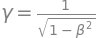

check: 1 - beta^2 = 9/25  (correct)   vs   1 - beta = 1/5  (exam: square dropped)


In [6]:
beta, gamma = sp.symbols("beta gamma", positive=True)
L, L0 = sp.symbols("L L_0", positive=True)
gamma_expr = 1 / sp.sqrt(1 - beta**2)
display(sp.Eq(gamma, gamma_expr))

b = sp.Rational(4, 5)
g = gamma_expr.subs(beta, b)
display(sp.Eq(sp.Symbol("gamma(beta=4/5)"), g))
print("check: 1 - beta^2 =", 1 - b**2, " (correct)   vs   1 - beta =", 1 - b, " (exam: square dropped)")

### 4.2 Q1.2: length contraction (exam: 268.328 km → correct: 360 km)

In [7]:
sol = teach("Q1.2", "length L of the 600 km mountain baseline as measured by Charlie",
            sp.Eq(L * gamma, L0), L,
            units="km (km / dimensionless gamma)",
            meaning="moving rulers are shortened along the motion; L < L0 because gamma > 1")
L_correct = sol[0].subs({L0: 600 * u.km, gamma: g})
display(sp.Eq(sp.Symbol("L"), L_correct))

# Reproduce the exam number to locate the error exactly
dropped = 600 * sp.sqrt(1 - b)          # = 600*sqrt(0.2)
as_written = 600 / sp.sqrt(1 - b)       # the fraction as written on the page
print(f"600*sqrt(1-0.8)  = {sp.N(dropped, 6)} km   <- matches the exam's 268.328 km")
print(f"600/sqrt(1-0.8)  = {sp.N(as_written, 6)} km  <- what the written fraction actually equals")
print("So two things went wrong: the square was dropped AND the written expression doesn't match the number.")
print("Sanity: L must be < 600 km (contraction) and > 0. 360 passes; 1341.6 would be dilation, which is impossible for a length.")

**[Q1.2] Quantity:** length L of the 600 km mountain baseline as measured by Charlie

Equation:


Isolated for L:


Units: km (km / dimensionless gamma)
Meaning: moving rulers are shortened along the motion; L < L0 because gamma > 1


600*sqrt(1-0.8)  = 268.328 km   <- matches the exam's 268.328 km
600/sqrt(1-0.8)  = 1341.64 km  <- what the written fraction actually equals
So two things went wrong: the square was dropped AND the written expression doesn't match the number.
Sanity: L must be < 600 km (contraction) and > 0. 360 passes; 1341.6 would be dilation, which is impossible for a length.


### 4.3 Q1.3: are the eruptions simultaneous for Charlie? (exam: "s = 0, true simultaneous" → no)

The Lorentz transformation for a frame moving at +v:

$$\Delta t' = \gamma\left(\Delta t - \frac{v\,\Delta x}{c^2}\right), \qquad \Delta x' = \gamma\,(\Delta x - v\,\Delta t).$$

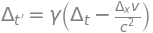

Delta_t' = t'_E - t'_B = -0.00266851*second  =  -2.669 ms
Delta_x' = 1000.0*kilometer
Interpretation: Delta_t' < 0, so Mt. E (the mountain Charlie is flying toward) erupts FIRST in Charlie's frame.


In [8]:
dt, dx, v, c = sp.symbols("Delta_t Delta_x v c", real=True)
dtp_expr = gamma * (dt - v * dx / c**2)
dxp_expr = gamma * (dx - v * dt)
display(sp.Eq(sp.Symbol("Delta_t'"), dtp_expr))
display(sp.Eq(sp.Symbol("Delta_x'"), dxp_expr))

subs = {dt: 0, dx: 600 * u.km, v: b * c_SI, c: c_SI, gamma: g}
dtp_exact, dtp_num = to(dtp_expr.subs(subs), u.second)
dxp_exact, dxp_num = to(dxp_expr.subs(subs), u.km)
display(sp.Eq(sp.Symbol("Delta_t'"), dtp_exact))
print(f"Delta_t' = t'_E - t'_B = {dtp_num}  =  {sp.N(dtp_exact / u.second * 1000, 4)} ms")
print(f"Delta_x' = {dxp_num}")
print("Interpretation: Delta_t' < 0, so Mt. E (the mountain Charlie is flying toward) erupts FIRST in Charlie's frame.")

In [9]:
# Spacetime interval, both frames (c = 1 units: c*t in km)
s2_S  = sp.Integer(0)**2 - 600**2
ctp   = g * (0 - b * 600)          # c*Delta_t' in km
xp    = g * (600 - b * 0)
s2_Sp = ctp**2 - xp**2
display(sp.Eq(sp.Symbol("s^2_ground"), s2_S), sp.Eq(sp.Symbol("s^2_Charlie"), s2_Sp))
print("c*dt' =", ctp, "km,  dx' =", xp, "km,  invariant?", s2_S == s2_Sp, ", spacelike?", s2_S < 0)

# What the exam computed: dt = 1/500 s was taken from 600 km / c (light-travel time), not from the problem
c_dt_exam = u.convert_to(c_SI * sp.Rational(1, 500) * u.second, u.km)
print(f"exam used c*(1/500 s) = {sp.N(c_dt_exam, 6)}, i.e. it plugged in a light signal's travel time,")
print("which forces s ~ 0 (lightlike). It never used the given fact dt = 0.")

c*dt' = -800 km,  dx' = 1000 km,  invariant? True , spacelike? True
exam used c*(1/500 s) = 599.585*kilometer, i.e. it plugged in a light signal's travel time,
which forces s ~ 0 (lightlike). It never used the given fact dt = 0.


**Why the spacetime interval "doesn't help here" (the grader's question):**
s² is **invariant**, meaning every observer computes the same value. Simultaneity is
**frame-dependent**. A frame-independent number can't tell you whether two events are
simultaneous in a particular frame. All s² does is classify the pair:

* s² < 0 (**spacelike**, which is the case here: s² = −(600 km)²). No signal could link the
  eruptions, so different frames can disagree about their order. In the ground frame they are
  simultaneous; for Charlie, Mt. E goes first by 2.67 ms.
* s² = 0 (**lightlike**) means the events lie on one light ray. It does *not* mean simultaneous.
  As the grader noted, s = 0 together with Δt = 0 would force Δx = 0, i.e. the same event.

The tool that answers "simultaneous for Charlie?" is the Lorentz transformation of Δt.

### 4.4 Q1.4: relativistic velocity addition (exam: −0.588 m/s → −0.909c)

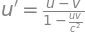

u'_correct = -0.9091 c = -2.725e+8*meter/second
exam (u = +0.4c, sign dropped) = -10/17 = -0.588  -> the exam's -0.588, with units 'm/s' instead of c
Galilean answer would be -6/5 c (faster than light: impossible)
Checks: |u'| < 1 ? True.  |u'| > 0.8 (the grader's 'should look like > 0.8c') ? True


In [10]:
uu, up = sp.symbols("u u'", real=True)
vel_add = sp.Eq(up, (uu - v) / (1 - uu * v / c**2))
display(vel_add)

def add(u_c, v_c):
    '''u' in units of c, rightward positive.'''
    return (u_c - v_c) / (1 - u_c * v_c)

u_rock, v_charlie = -sp.Rational(2, 5), sp.Rational(4, 5)
up_correct = add(u_rock, v_charlie)
up_exam = add(+sp.Rational(2, 5), v_charlie)
display(sp.Eq(sp.Symbol("u'_correct/c"), up_correct))
print(f"u'_correct = {sp.N(up_correct, 4)} c = {sp.N(up_correct * c_SI, 4)}")
print(f"exam (u = +0.4c, sign dropped) = {up_exam} = {sp.N(up_exam, 3)}  -> the exam's -0.588, with units 'm/s' instead of c")
print(f"Galilean answer would be {u_rock - v_charlie} c (faster than light: impossible)")
print(f"Checks: |u'| < 1 ? {abs(up_correct) < 1}.  |u'| > 0.8 (the grader's 'should look like > 0.8c') ? {abs(up_correct) > sp.Rational(4,5)}")

**Sign logic:** with +x to the right, the rock's velocity is **u = −0.4c**. That minus sign has to
go into the formula. Charlie flies right and the rock comes left, so they close on each other, and
in Charlie's frame the rock must approach *faster* than 0.8c. A magnitude below 0.8c (like 0.588)
fails a quick check before any arithmetic. Relativity caps the result below c: 10/11 ≈ 0.909.
The minus sign in the answer means the rock moves to the left in Charlie's frame.

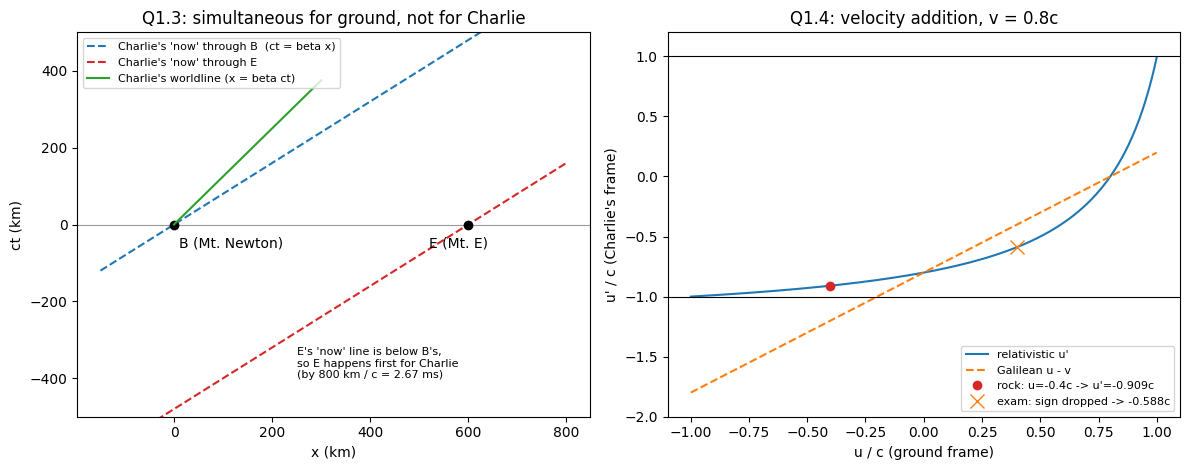

In [11]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8))

# Minkowski diagram (ground frame, c = 1, km)
x = np.linspace(-150, 800, 2)
bt = float(b)
ax1.axhline(0, color="0.6", lw=0.8)
ax1.plot(x, bt * (x - 0), "C0--", label="Charlie's 'now' through B  (ct = beta x)")
ax1.plot(x, bt * (x - 600), "C3--", label="Charlie's 'now' through E")
ax1.plot([0], [0], "ko"); ax1.annotate("B (Mt. Newton)", (0, 0), (10, -60))
ax1.plot([600], [0], "ko"); ax1.annotate("E (Mt. E)", (600, 0), (520, -60))
ax1.plot(np.linspace(0, 300, 2), np.linspace(0, 300, 2) / bt, "C2", label="Charlie's worldline (x = beta ct)")
ax1.set_xlabel("x (km)"); ax1.set_ylabel("ct (km)")
ax1.set_title("Q1.3: simultaneous for ground, not for Charlie")
ax1.set_ylim(-500, 500); ax1.legend(fontsize=8, loc="upper left")
ax1.text(250, -400, "E's 'now' line is below B's,\nso E happens first for Charlie\n(by 800 km / c = 2.67 ms)", fontsize=8)

# Velocity addition curve for v = 0.8c
uu_grid = np.linspace(-0.999, 0.999, 400)
ax2.plot(uu_grid, (uu_grid - 0.8) / (1 - 0.8 * uu_grid), label="relativistic u'")
ax2.plot(uu_grid, uu_grid - 0.8, "--", label="Galilean u - v")
ax2.axhline(-1, color="k", lw=0.8); ax2.axhline(1, color="k", lw=0.8)
ax2.plot([-0.4], [float(up_correct)], "C3o", label="rock: u=-0.4c -> u'=-0.909c")
ax2.plot([0.4], [float(up_exam)], "C1x", ms=10, label="exam: sign dropped -> -0.588c")
ax2.set_xlabel("u / c (ground frame)"); ax2.set_ylabel("u' / c (Charlie's frame)")
ax2.set_title("Q1.4: velocity addition, v = 0.8c"); ax2.legend(fontsize=8); ax2.set_ylim(-2, 1.2)
plt.tight_layout(); plt.show()

## 5. Photoelectric-effect corrections (Q2)

Einstein's photoelectric equation, plus the stopping-potential and kinetic-energy relations:

$$K_{max} = hf - \phi, \qquad K_{max} = eV_s, \qquad f = \frac{c}{\lambda}, \qquad K_{max} = \tfrac12 m_e v_{max}^2.$$

**Stated assumption (status `ASSUMPTION`):** V_s = 5.7 V is the stopping potential. The grader
questioned this ("at what potential is qΔV = K_max?"), so check it against the original prompt.

In [12]:
h, f, lam, phi, K, e, Vs, m, vmax = sp.symbols("h f lambda phi K_max e V_s m_e v_max", positive=True)
c_ = sp.Symbol("c", positive=True)

teach("Q2.1a", "photon frequency f", sp.Eq(c_, f * lam), f, "Hz = 1/s", "frequency, not wavelength, multiplies h")
teach("Q2.2", "work function phi", sp.Eq(K, h * f - phi), phi, "J (or eV)",
      "minimum energy to free an electron; must be POSITIVE")
teach("Q2.1b", "max photoelectron speed", sp.Eq(e * Vs, sp.Rational(1, 2) * m * vmax**2), vmax, "m/s",
      "the stopping potential's energy eVs equals K_max of the fastest electrons")

**[Q2.1a] Quantity:** photon frequency f

Equation:


Isolated for f:


Units: Hz = 1/s
Meaning: frequency, not wavelength, multiplies h


**[Q2.2] Quantity:** work function phi

Equation:


Isolated for phi:


Units: J (or eV)
Meaning: minimum energy to free an electron; must be POSITIVE


**[Q2.1b] Quantity:** max photoelectron speed

Equation:


Isolated for v_max:


Units: m/s
Meaning: the stopping potential's energy eVs equals K_max of the fastest electrons


In [13]:
lam_v, Vs_v = 178 * u.nm, sp.Rational(57, 10) * u.volt

f_v = u.convert_to(c_SI / lam_v, 1 / u.second)
E_ph = u.convert_to(h_SI * f_v, u.joule)
K_v = u.convert_to(e_SI * Vs_v, u.joule)
phi_v = u.convert_to(E_ph - K_v, u.joule)
v_v = u.convert_to(sp.sqrt(2 * K_v / me_SI), u.meter / u.second)

rows = [("photon frequency f = c/lambda", f_v, None),
        ("photon energy hf", E_ph, E_ph / eV),
        ("K_max = e Vs", K_v, K_v / eV),
        ("work function phi = hf - eVs", phi_v, phi_v / eV),
        ("v_max = sqrt(2 K_max / m_e)", v_v, None)]
for name, q, q_eV in rows:
    extra = f"   = {sp.N(q_eV, 5)} eV" if q_eV is not None else ""
    print(f"{name:32s} {sp.N(q, 5)}{extra}")
print(f"v_max / c = {sp.N(v_v / c_SI, 3)}  -> nonrelativistic, so (1/2) m v^2 is fine")

photon frequency f = c/lambda    1.6842e+15/second
photon energy hf                 1.116e-18*joule   = 6.9654 eV
K_max = e Vs                     9.1324e-19*joule   = 5.7000 eV
work function phi = hf - eVs     2.0274e-19*joule   = 1.2654 eV
v_max = sqrt(2 K_max / m_e)      1.416e+6*meter/second
v_max / c = 0.00472  -> nonrelativistic, so (1/2) m v^2 is fine


**Reproducing the exam's Q2.2 number shows exactly what went wrong.** The exam put **h × λ**
where **h × f** belongs:

In [14]:
h_r, m_r = sp.Float("6.63e-34"), sp.Float("9.11e-31")
exam_phi = h_r * sp.Float("178e-9") - sp.Rational(1, 2) * m_r * sp.Float("1.41e6")**2
print("exam: 6.63e-34 * 178e-9 - 0.5*9.11e-31*(1.41e6)^2 =", sp.N(exam_phi, 4), " (matches -9.05e-19)")

print("dimension of h*lambda :", dimension_of(h_SI * lam_v), "  <- J*m*s, not an energy")
print("dimension of h*f      :", dimension_of(h_SI * f_v))
print("so the h*lambda term (1.18e-40) is numerically ~0; the result is just -K_max, giving a NEGATIVE phi.")
print("A negative work function means electrons leave the metal with energy to spare at zero light: unphysical.")
print("\nSame mistake in Q2.3: 6.63e-34 * 178e-9 =", sp.N(h_r * sp.Float("178e-9"), 3), "(J*s*m) is not a photon energy.")

exam: 6.63e-34 * 178e-9 - 0.5*9.11e-31*(1.41e6)^2 = -9.056e-19  (matches -9.05e-19)
dimension of h*lambda : Dimension(energy*length*time)   <- J*m*s, not an energy
dimension of h*f      : Dimension(energy)
so the h*lambda term (1.18e-40) is numerically ~0; the result is just -K_max, giving a NEGATIVE phi.
A negative work function means electrons leave the metal with energy to spare at zero light: unphysical.

Same mistake in Q2.3: 6.63e-34 * 178e-9 = 1.18e-40 (J*s*m) is not a photon energy.


**Interpretation flag on φ ≈ 1.27 eV.** That is lower than the work function of any common pure
metal (cesium is about 2.1 eV). Either the problem uses a made-up material, or 5.7 V is not the
stopping potential, which is exactly the grader's question. Check the original prompt.

**Wrong-equation warning:** the hydrogen formula E_n = −13.6 eV / n² describes bound states of
*hydrogen*. It has no role in finding a metal's work function.

### 5.1 Q2.3: beam power from a photon rate (needs `MISSING_SOURCE_GRAPH`)

$$P = \frac{dN}{dt}\,hf = R\,\frac{hc}{\lambda}.$$

The rate R = dN/dt (photons per second) has to be read from the original graph, e.g. as a
slope of N versus t. The scan doesn't include the graph, so no number is given here.

In [15]:
R = sp.Symbol("R", positive=True)
P_expr = R * h * c_ / lam
display(sp.Eq(sp.Symbol("P"), P_expr))
print("units: (1/s) * J = W")
if MISSING_SOURCE_GRAPH_Q2_3 is None:
    print("MISSING_SOURCE_GRAPH: R = dN/dt is not in the scan. Set MISSING_SOURCE_GRAPH_Q2_3 = R in photons/s.")
    print("Per-photon energy that multiplies R:", sp.N(E_ph, 5), "=", sp.N(E_ph / eV, 5), "eV")
else:
    P_num = u.convert_to(MISSING_SOURCE_GRAPH_Q2_3 / u.second * E_ph, u.watt)
    print("P =", sp.N(P_num, 4))

units: (1/s) * J = W
MISSING_SOURCE_GRAPH: R = dN/dt is not in the scan. Set MISSING_SOURCE_GRAPH_Q2_3 = R in photons/s.
Per-photon energy that multiplies R: 1.116e-18*joule = 6.9654 eV


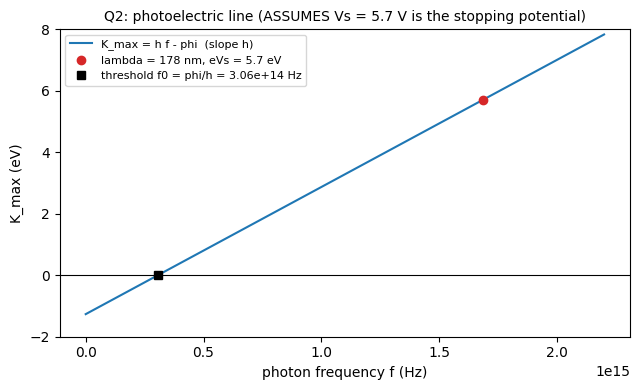

In [16]:
# Plot: Einstein line K_max(f) = h f - phi under the 5.7 V assumption
h_eVs = float(h_SI / eV / u.second)
phi_eV = float(phi_v / eV)
f_grid = np.linspace(0, 2.2e15, 200)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(f_grid, h_eVs * f_grid - phi_eV, label="K_max = h f - phi  (slope h)")
ax.axhline(0, color="k", lw=0.8)
ax.plot([float(f_v / (1 / u.second))], [5.7], "C3o", label="lambda = 178 nm, eVs = 5.7 eV")
ax.plot([phi_eV / h_eVs], [0], "ks", label=f"threshold f0 = phi/h = {phi_eV / h_eVs:.2e} Hz")
ax.set_xlabel("photon frequency f (Hz)"); ax.set_ylabel("K_max (eV)")
ax.set_title("Q2: photoelectric line (ASSUMES Vs = 5.7 V is the stopping potential)", fontsize=10)
ax.legend(fontsize=8); ax.set_ylim(-2, 8); plt.tight_layout(); plt.show()

## 6. Electromagnetism and photon corrections (Q3)

### 6.1 Q3.1 / Q3.2: Lorentz force and direction finding

$$\vec F = q\left(\vec E + \vec v \times \vec B\right)$$

**Procedure:**
1. Use the right-hand rule for **v × B**: fingers along v, curl toward B, thumb gives v × B.
2. **Then apply the sign of q.** For a positive charge F points along v × B; for a negative charge
   it flips to −v × B.
3. With an E field present, add qE as a vector. **E and B are never added to each other directly** (see 6.2).

The cell below computes the direction from components. The example uses the orientation in the
Q3.2 margin sketch (v to the right = +x̂, B up = +ŷ, out of page = +ẑ). This sketch reading is
uncertain, and the sub-part prompts are `MISSING_SOURCE_FIGURE`.

In [17]:
xh, yh, zh = sp.Matrix([1, 0, 0]), sp.Matrix([0, 1, 0]), sp.Matrix([0, 0, 1])
names = {(1, 0, 0): "+x (right)", (-1, 0, 0): "-x (left)", (0, 1, 0): "+y (up)", (0, -1, 0): "-y (down)",
         (0, 0, 1): "+z (out of page)", (0, 0, -1): "-z (into page)"}

def force_dir(q_sign, vvec, Bvec):
    F = q_sign * vvec.cross(Bvec)
    return names.get(tuple(int(sp.sign(c)) for c in F), str(list(F)))

for q_sign, label in [(+1, "positive"), (-1, "negative")]:
    print(f"v = +x, B = +y, q {label:8s}: F along {force_dir(q_sign, xh, yh)}")
print("(Q3.2 figure missing: compare with the original diagram before re-grading those sub-parts.)")

v = +x, B = +y, q positive: F along +z (out of page)
v = +x, B = +y, q negative: F along -z (into page)
(Q3.2 figure missing: compare with the original diagram before re-grading those sub-parts.)


### 6.2 Q3.3: velocity selector (blank on the exam → v = E/B ≈ 6.67 × 10⁶ m/s)

**Assumption:** "|E| ⊥ |B|, find v" is read as the speed at which the charge passes **undeflected**,
with E ⊥ B ⊥ v and the electric and magnetic forces cancelling.

In [18]:
q, E_, B_, v_ = sp.symbols("q E B v", positive=True)
sol = teach("Q3.3", "speed of an undeflected charge in crossed E and B",
            sp.Eq(q * E_, q * v_ * B_), v_,
            units="(V/m)/T = m/s",
            meaning="only this speed passes straight through; independent of q and m (B != 0 required)")

E_v, B_v = 200000 * u.volt / u.meter, sp.Rational(3, 100) * u.tesla
v_sel = u.convert_to(E_v / B_v, u.meter / u.second)
print(f"v = {v_sel} = {sp.N(v_sel, 4)};  v/c = {sp.N(v_sel / c_SI, 3)} (nonrelativistic)")

print("\nWhy E + B (or any sum of their magnitudes) is meaningless:")
try:
    dimension_of(E_v + B_v)
except ValueError as err:
    print("  SymPy refuses:", err)
print("  V/m and T are different dimensions; only the ratio E/B has a physical reading (a speed).")

**[Q3.3] Quantity:** speed of an undeflected charge in crossed E and B

Equation:


Isolated for v:


Units: (V/m)/T = m/s
Meaning: only this speed passes straight through; independent of q and m (B != 0 required)
v = 20000000*meter/(3*second) = 6.667e+6*meter/second;  v/c = 0.0222 (nonrelativistic)

Why E + B (or any sum of their magnitudes) is meaningless:
  SymPy refuses: Dimension of "200000*volt/meter" is Dimension(voltage/length), but it should be Dimension(magnetic_density)
  V/m and T are different dimensions; only the ratio E/B has a physical reading (a speed).


### 6.3 Q3.4: photon wavelength (exam: n = 3 from the hydrogen formula → see below)

For a free photon of energy E:

$$E = hf = \frac{hc}{\lambda} \;\Rightarrow\; \lambda = \frac{hc}{E}.$$

In [19]:
Eph, h2, c2, lam2 = sp.symbols("E h c lambda", positive=True)
teach("Q3.4", "wavelength of a 10 eV photon", sp.Eq(Eph, h2 * c2 / lam2), lam2,
      "J*s*(m/s)/J = m", "higher photon energy -> shorter wavelength; 10 eV is ultraviolet")
lam10 = u.convert_to(h_SI * c_SI / (10 * eV), u.nm)
print("lambda(10 eV) =", sp.N(lam10, 5))

n = sp.Symbol("n", positive=True)
print("\nThe exam's equation 10 eV = -13.6 eV / n^2 over positive n:", sp.solve(sp.Eq(10, -sp.Rational(136, 10) / n**2), n))
print("Over all complex n:", sp.solve(sp.Eq(10, -sp.Rational(136, 10) / sp.Symbol('n')**2)))
print("Positive left side, negative right side: there is NO real n. The boxed 3 can't come from this equation.")

**[Q3.4] Quantity:** wavelength of a 10 eV photon

Equation:


Isolated for lambda:


Units: J*s*(m/s)/J = m
Meaning: higher photon energy -> shorter wavelength; 10 eV is ultraviolet
lambda(10 eV) = 123.98*nanometer

The exam's equation 10 eV = -13.6 eV / n^2 over positive n: []
Over all complex n: [-sqrt(34)*I/5, sqrt(34)*I/5]
Positive left side, negative right side: there is NO real n. The boxed 3 can't come from this equation.


**What the grader is pointing at ("only for hydrogen – use the energy diagram"):** the question
asks for photon wavelength**s**. That points to an energy-level diagram (probably not hydrogen)
in the original exam. The usual method:

1. Read the levels E₁, E₂, … from the diagram.
2. Work out which upper levels the 10 eV can reach (for an electron collision, any level with
   E_k − E₁ ≤ 10 eV).
3. Each downward transition i → j gives a photon with λ = hc / (E_i − E_j).

The function below does this once `MISSING_SOURCE_ENERGY_DIAGRAM_Q3_4` is filled in. Until then
it refuses rather than guessing.

In [20]:
def emission_wavelengths(levels_eV, available_eV):
    '''levels_eV: list of level energies (eV) incl. ground; returns transitions reachable from ground.'''
    lv = sorted(levels_eV)
    reach = [E for E in lv if E - lv[0] <= available_eV]
    hc_eV_nm = float(u.convert_to(h_SI * c_SI, u.joule * u.nm) / (eV * u.nm))
    out = []
    for i, Ei in enumerate(reach):
        for Ej in reach[:i]:
            out.append((Ei, Ej, Ei - Ej, hc_eV_nm / (Ei - Ej)))
    return pd.DataFrame(out, columns=["E_upper_eV", "E_lower_eV", "photon_eV", "lambda_nm"])

if MISSING_SOURCE_ENERGY_DIAGRAM_Q3_4 is None:
    print("MISSING_SOURCE_ENERGY_DIAGRAM: the Q3.4 level diagram is not in the scan; no transition list computed.")
else:
    display(emission_wavelengths(MISSING_SOURCE_ENERGY_DIAGRAM_Q3_4, 10))

MISSING_SOURCE_ENERGY_DIAGRAM: the Q3.4 level diagram is not in the scan; no transition list computed.


## 7. Numerical sanity checks

Each check is a `numpy` / `assert` test on the numbers above. A failing check stops the notebook.
These checks catch arithmetic and consistency errors. They don't show the model is correct.

In [21]:
fl = lambda q, unit: float(u.convert_to(q, unit) / unit)
checks = []
def check(name, ok):
    checks.append((name, bool(ok)))
    assert ok, name

check("gamma(0.8) = 5/3", g == sp.Rational(5, 3))
check("L*gamma = L0 (360 * 5/3 = 600)", sp.Rational(360) * g == 600)
check("0 < L < L0", 0 < 360 < 600)
check("dt' = -800 km / c ~ -2.67 ms", np.isclose(fl(dtp_exact, u.second), -2.6685e-3, rtol=1e-4))
check("interval invariant", s2_S == s2_Sp)
check("events are spacelike", s2_S < 0)
check("|u'| < c", abs(float(up_correct)) < 1)
check("|u'| > 0.8c (closing speed exceeds Charlie's)", abs(float(up_correct)) > 0.8)
check("u' = -10/11", up_correct == -sp.Rational(10, 11))
check("photon energy ~ 6.97 eV", np.isclose(float(E_ph / eV), 6.9654, atol=1e-3))
check("phi ~ 1.27 eV", np.isclose(float(phi_v / eV), 1.2654, atol=1e-3))
check("phi > 0", float(phi_v / eV) > 0)
check("v_max ~ 1.416e6 m/s", np.isclose(fl(v_v, u.meter / u.second), 1.416e6, rtol=1e-3))
check("back-substitution: hf - phi = e Vs", sp.simplify(E_ph - phi_v - K_v) == 0)
check("exam rounding gives same v_max to 0.1%", np.isclose(np.sqrt(2 * 1.60e-19 * 5.7 / 9.11e-31), 1.416e6, rtol=2e-3))
check("v_selector = 6.67e6 m/s", np.isclose(fl(v_sel, u.meter / u.second), 6.6667e6, rtol=1e-4))
check("v_selector << c", fl(v_sel, u.meter / u.second) < 0.1 * 299792458)
check("lambda(10 eV) ~ 124 nm", np.isclose(fl(lam10, u.nm), 123.98, atol=0.01))
check("E*lambda = hc round trip", np.isclose(10 * fl(lam10, u.nm), 1239.84, atol=0.01))

display(pd.DataFrame(checks, columns=["check", "passed"]))
print(f"{sum(ok for _, ok in checks)}/{len(checks)} numerical checks passed")

,check,passed
0,gamma(0.8) = 5/3,True
1,L*gamma = L0 (360 * 5/3 = 600),True
2,0 < L < L0,True
3,dt' = -800 km / c ~ -2.67 ms,True
4,interval invariant,True
5,events are spacelike,True
6,|u'| < c,True
7,|u'| > 0.8c (closing speed exceeds Charlie's),True
8,u' = -10/11,True
9,photon energy ~ 6.97 eV,True


19/19 numerical checks passed


## 8. Lean proof obligations and compilation status

The file `lean/phys106_midterm1_proofs.lean` (Lean 4 + Mathlib) states the algebra behind each
correction as theorems: isolations with their nonzero hypotheses, the residual forms, and exact
rational arithmetic in c = 1 units. **It proves algebra, not physics.**

Lean runs **separately from Python**. The next cell only reads the file and lists its theorems.
The cell after it is an **optional** checker: it runs `lake env lean` from a Lake project that has
Mathlib. A theorem is labelled `VERIFIED` only if that command exits with code 0 in this run.
Otherwise everything is labelled `UNVERIFIED`.

In [22]:
LEAN_FILE = Path.cwd().parent / "lean" / "phys106_midterm1_proofs.lean"
if not LEAN_FILE.exists():
    LEAN_FILE = Path.cwd() / "lean" / "phys106_midterm1_proofs.lean"
lean_src = LEAN_FILE.read_text(encoding="utf-8")
theorems = re.findall(r"^theorem\s+(\S+)", lean_src, flags=re.M)
obligations = {
    "length_contraction_isolate": "1. length contraction algebra (L*gamma = L0 -> L = L0/gamma, gamma != 0)",
    "length_contraction_600km": "1. 600 km / gamma(0.8) = 360 km",
    "photoelectric_residual": "2. photoelectric residual K - h f + phi = 0",
    "velocity_selector_isolate": "3. E = v B -> v = E/B under B != 0",
    "photon_energy_residual": "4. photon energy residual E - hbar*omega = 0",
}
print(f"{LEAN_FILE.name}: {len(theorems)} theorems")
for t in theorems:
    print(f"  {t:40s} {obligations.get(t, '')}")

phys106_midterm1_proofs.lean: 25 theorems
  one_sub_beta_sq                          
  dropped_square_is_wrong                  
  sqrt_one_sub_beta_sq                     
  gamma_four_fifths                        
  length_contraction_isolate               1. length contraction algebra (L*gamma = L0 -> L = L0/gamma, gamma != 0)
  length_contraction_600km                 1. 600 km / gamma(0.8) = 360 km
  not_simultaneous                         
  simultaneity_numbers                     
  dx_prime_numbers                         
  interval_invariant                       
  interval_numbers                         
  interval_spacelike                       
  velocity_addition_numbers                
  velocity_addition_sign_error             
  velocity_addition_subluminal             
  photoelectric_residual                   2. photoelectric residual K - h f + phi = 0
  work_function_isolate                    
  work_function_pos                        
  vmax_isolate      

In [23]:
# OPTIONAL Lean check: separate from all physics cells above. Set RUN_LEAN = False to skip.
import os
RUN_LEAN = True
LEAN_PROJECT = Path(os.environ.get("PHYS106_LEAN_PROJECT", Path.home() / "lean" / "NavierStokesAndEuler"))

lake = shutil.which("lake")
lean_status = "UNVERIFIED (Lean check not run)"
if not RUN_LEAN:
    print("RUN_LEAN = False: Lean snippets are UNVERIFIED in this run.")
elif lake is None:
    print("Lean/lake not found on PATH: Lean snippets are UNVERIFIED. Install elan + Mathlib to check them.")
elif not (LEAN_PROJECT / "lake-manifest.json").exists() or "mathlib" not in (LEAN_PROJECT / "lake-manifest.json").read_text():
    print(f"No Mathlib Lake project at {LEAN_PROJECT}: Lean snippets are UNVERIFIED.")
    print("Set PHYS106_LEAN_PROJECT to a Lake project that requires Mathlib.")
else:
    print(f"running: lake env lean {LEAN_FILE}\n   (cwd = {LEAN_PROJECT}; first run can take a few minutes)")
    r = subprocess.run([lake, "env", "lean", str(LEAN_FILE)], cwd=LEAN_PROJECT,
                       capture_output=True, text=True, timeout=1800)
    msgs = (r.stdout + r.stderr).strip()
    print("exit code:", r.returncode)
    print(msgs if msgs else "(no errors or warnings)")
    lean_status = "VERIFIED (lake env lean exit 0)" if r.returncode == 0 and "error" not in msgs else "FAILED, see messages"

display(pd.DataFrame({"theorem": theorems, "status": lean_status}))

running: lake env lean D:\Summer2026\Dispersion-Assisted-GS-Phase-Recovery\.claude\worktrees\phys106-midterm-sympy-lean-c8e910\lean\phys106_midterm1_proofs.lean
   (cwd = C:\Users\mrjel\lean\NavierStokesAndEuler; first run can take a few minutes)

exit code: 0
(no errors or warnings)


,theorem,status
0,one_sub_beta_sq,VERIFIED (lake env lean exit 0)
1,dropped_square_is_wrong,VERIFIED (lake env lean exit 0)
2,sqrt_one_sub_beta_sq,VERIFIED (lake env lean exit 0)
3,gamma_four_fifths,VERIFIED (lake env lean exit 0)
4,length_contraction_isolate,VERIFIED (lake env lean exit 0)
5,length_contraction_600km,VERIFIED (lake env lean exit 0)
6,not_simultaneous,VERIFIED (lake env lean exit 0)
7,simultaneity_numbers,VERIFIED (lake env lean exit 0)
8,dx_prime_numbers,VERIFIED (lake env lean exit 0)
9,interval_invariant,VERIFIED (lake env lean exit 0)


## 9. Exam-review practice questions

Try each one before running the answer cell. They target the same skills the exam missed.

1. A 1.0 km runway is passed by a ship at β = 0.6. How long is the runway in the ship's frame?
   (Don't drop the square.)
2. Two lamps 3000 km apart flash simultaneously in the ground frame. A rocket flies from the
   first lamp toward the second at 0.6c. Which flashes first for the rocket, and by how much?
3. Spaceship A moves right at 0.6c. Ship B moves left at 0.6c. Find B's velocity in A's frame,
   with the sign.
4. Light of λ = 250 nm hits a metal with φ = 2.3 eV. Find K_max, V_s, and v_max.
5. A 1.0 mW laser at 633 nm: how many photons per second? (P = R·hc/λ, solved for R.)
6. *Hydrogen analogue for the energy-diagram method (not the exam's diagram):* an electron with
   12.8 eV of kinetic energy hits ground-state hydrogen. Which photon wavelengths can come out?

In [24]:
gm = lambda bb: 1 / sp.sqrt(1 - bb**2)
b6 = sp.Rational(3, 5)
print("1.", sp.N(1 / gm(b6), 4), "km   (gamma = 5/4, L = 0.8 km)")
dtp1 = gm(b6) * (0 - b6 * 3000)       # c*dt' in km
print(f"2. c*dt' = {dtp1} km -> dt' = {sp.N(u.convert_to(dtp1 * u.km / c_SI, u.second) / u.second * 1e3, 4)} ms; negative, so the FAR lamp (ahead of the rocket) flashes first")
print("3. u' =", add(-b6, b6), "c =", sp.N(add(-b6, b6), 4), "c  (leftward, below c)")
E250 = u.convert_to(h_SI * c_SI / (250 * u.nm), u.joule)
K4 = E250 - sp.Rational(23, 10) * eV
print(f"4. hf = {sp.N(E250 / eV, 4)} eV, K_max = {sp.N(K4 / eV, 4)} eV, Vs = {sp.N(K4 / eV, 4)} V, "
      f"v_max = {sp.N(u.convert_to(sp.sqrt(2 * K4 / me_SI), u.meter / u.second), 4)}")
R5 = u.convert_to(sp.Rational(1, 1000) * u.watt / (h_SI * c_SI / (633 * u.nm)), 1 / u.second)
print("5. R =", sp.N(R5, 4))
H_levels = [-13.6 / k**2 for k in range(1, 8)]
print("6. hydrogen levels reachable with 12.8 eV: n <= 4 (n=5 needs 13.06 eV):")
display(emission_wavelengths(H_levels, 12.8).round(2))
print("   With only 10 eV the answer is NONE: hydrogen's first excitation needs 10.2 eV.")

1. 0.8000 km   (gamma = 5/4, L = 0.8 km)
2. c*dt' = -2250 km -> dt' = -7.505 ms; negative, so the FAR lamp (ahead of the rocket) flashes first
3. u' = -15/17 c = -0.8824 c  (leftward, below c)
4. hf = 4.959 eV, K_max = 2.659 eV, Vs = 2.659 V, v_max = 9.672e+5*meter/second
5. R = 3.187e+15/second
6. hydrogen levels reachable with 12.8 eV: n <= 4 (n=5 needs 13.06 eV):


,E_upper_eV,E_lower_eV,photon_eV,lambda_nm
0,-3.40,-13.60,10.20,121.55
1,-1.51,-13.60,12.09,102.56
2,-1.51,-3.40,1.89,656.39
3,-0.85,-13.60,12.75,97.24
4,-0.85,-3.40,2.55,486.21
5,-0.85,-1.51,0.66,1875.39


   With only 10 eV the answer is NONE: hydrogen's first excitation needs 10.2 eV.


## 10. Information still needed from the original exam

| Item | Placeholder | Why it matters |
|---|---|---|
| Full printed text of Q1 (all parts) | — | Confirms the 600 km is the proper length, the mountains' left/right order, and Charlie's direction. |
| Q1.1 answer choices | `MISSING_SOURCE_CHOICES_Q1_1` | Answer "a" was marked correct, but the options aren't visible. |
| Q2.1 prompt / setup or graph | — | **Whether 5.7 V is the stopping potential** (the grader questioned it). φ and v_max depend on this. |
| Q2.3 graph | `MISSING_SOURCE_GRAPH_Q2_3` | R = dN/dt (or another slope) is needed to compute the power P. |
| Q2.4 prompt and choices | `MISSING_SOURCE_PROMPT_Q2_4` | Not covered at all here. |
| Q3.1 answer choices | `MISSING_SOURCE_CHOICES_Q3_1` | "C" was marked correct. |
| Q3.2 figure and sub-part prompts | `MISSING_SOURCE_FIGURE_Q3_2` | Needed to re-grade the force directions. The red circles are ambiguous. |
| Q3.3 full prompt | — | Confirms the "undeflected / velocity selector" reading and which particle it is. |
| Q3.4 energy-level diagram | `MISSING_SOURCE_ENERGY_DIAGRAM_Q3_4` | Needed for the list of photon wavelengths. 124 nm is only the 10 eV photon. |
| Point values per part | — | The red numbers show points earned, not points possible. |

## Checklist: conceptual errors corrected

- [x] **Q1.2:** γ uses **1 − β²**, not 1 − β. The written fraction (600/√0.2) also didn't match the computed number (600·√0.2). Correct: L = L₀/γ = 360 km.
- [x] **Q1.3:** A frame-independent invariant (s²) can't decide a frame-dependent question (simultaneity). Use Δt′ = γ(Δt − vΔx/c²): Δt′ = −2.67 ms, Mt. E first. s = 0 means lightlike, not simultaneous. Δt = 0 was given; it shouldn't be replaced with a light-travel time.
- [x] **Q1.4:** Put the **sign** of the velocity into the formula (u = −0.4c), and report u′ in units of c, not m/s. Quick check: the closing speed must exceed 0.8c. u′ = −10/11 c ≈ −0.909c.
- [x] **Q2.2 / Q2.3:** use **f = c/λ**, never λ, wherever hf appears. h·λ has units J·s·m. A **negative work function** is an automatic red flag.
- [x] **Q2.1:** Confirm which potential is the *stopping* potential before setting eV = K_max (still open: see §10).
- [x] **Q3.3:** In crossed fields, balance **forces**: qE = qvB, so v = E/B ≈ 6.67 × 10⁶ m/s. E and B have different dimensions and can't be added.
- [x] **Q3.4:** E_n = −13.6 eV/n² is **hydrogen only**, and it had no real solution here anyway. A free photon has λ = hc/E = 124 nm at 10 eV. Transition wavelengths come from the exam's energy diagram.

**Status of each kind of claim:** the **tutoring corrections** above are explanations. The
**numerical model** results passed the §7 checks, which test consistency, not the inputs. The
**formally verified** statements are only the Lean theorems in §8, and only if that cell printed
`VERIFIED` in this run. All of them are algebraic facts about the models, not proofs of physics.